<a href="https://colab.research.google.com/github/ali-akbar-bermano/Lecture-series_ALI-AKBAR-BERMANO_G1A024041/blob/main/Implementasi_lecture_series_pertemuan_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Perkalian Matriks (Serial vs Paralel Multiprocessing) & Pengukuran GFLOPS.**

1. Cek Spesifikasi CPU Google Colab

In [2]:
import os
import multiprocessing
import platform

def check_cpu_specs():
    print("=== SPESIFIKASI CPU GOOGLE COLAB ===")
    print(f"Sistem Operasi       : {platform.system()} {platform.release()}")
    print(f"Arsitektur Processor : {platform.machine()}")
    print(f"Jumlah CPU Core      : {os.cpu_count()} Cores")
    print("===================================\n")

check_cpu_specs()

=== SPESIFIKASI CPU GOOGLE COLAB ===
Sistem Operasi       : Linux 6.6.122+
Arsitektur Processor : x86_64
Jumlah CPU Core      : 2 Cores



2. Fungsi Perkalian Matriks Serial (1 Core)

In [3]:
import numpy as np
import time

def matrix_multiply_serial(A, B):
    """
    Menghitung perkalian matriks A dan B secara serial (1 core).
    """
    start_time = time.time()

    # Perkalian matriks menggunakan NumPy (Single Thread untuk benchmark murni)
    # Catatan: Kita gunakan np.matmul/dot murni untuk mempercepat perhitungan dasar
    result = np.dot(A, B)

    elapsed_time = time.time() - start_time
    return result, elapsed_time

3. Fungsi Worker & Paralelisasi Multiprocessing (Multi-Core)

In [1]:
def _worker_multiply_rows(args):
    """
    Fungsi pembantu (worker) untuk memproses sebagian baris matriks A dikalikan matriks B.
    """
    sub_A, B = args
    return np.dot(sub_A, B)

def matrix_multiply_parallel(A, B, num_workers=None):
    """
    Menghitung perkalian matriks A dan B secara paralel memanfaatkan multiprocessing.
    """
    if num_workers is None:
        num_workers = os.cpu_count()

    start_time = time.time()

    # Membagi matriks A menjadi beberapa bagian sesuai jumlah CPU Core
    A_chunks = np.array_split(A, num_workers, axis=0)
    tasks = [(chunk, B) for chunk in A_chunks]

    # Menggunakan Multiprocessing Pool untuk mengeksekusi secara paralel
    with multiprocessing.Pool(processes=num_workers) as pool:
        results = pool.map(_worker_multiply_rows, tasks)

    # Menggabungkan kembali hasil dari semua worker
    result = np.vstack(results)

    elapsed_time = time.time() - start_time
    return result, elapsed_time

4. Fungsi Penghitung FLOPS (Floating Point Operations)

In [5]:
def calculate_gflops(N, elapsed_time):
    """
    Hitung GFLOPS untuk perkalian matriks ukuran N x N.
    Total operasi FLOPs untuk matriks N x N x N adalah 2 * (N^3).
    """
    total_flops = 2.0 * (N ** 3)
    gflops = (total_flops / elapsed_time) / 1e9
    return gflops

5. Main Execution & Visualisasi Hasil Benchmark

--- MULAI BENCHMARK HPC (Menggunakan 2 Cores) ---

Memproses Matriks Ukuran: 500 x 500...
  > Waktu Serial   : 0.0098 detik
  > Waktu Paralel  : 0.0773 detik
  > Speedup        : 0.13x lebih cepat
  > Performansi    : 3.24 GFLOPS

Memproses Matriks Ukuran: 1000 x 1000...
  > Waktu Serial   : 0.0598 detik
  > Waktu Paralel  : 0.2488 detik
  > Speedup        : 0.24x lebih cepat
  > Performansi    : 8.04 GFLOPS

Memproses Matriks Ukuran: 1500 x 1500...
  > Waktu Serial   : 0.2219 detik
  > Waktu Paralel  : 0.5981 detik
  > Speedup        : 0.37x lebih cepat
  > Performansi    : 11.29 GFLOPS

Memproses Matriks Ukuran: 2000 x 2000...
  > Waktu Serial   : 0.4694 detik
  > Waktu Paralel  : 1.1776 detik
  > Speedup        : 0.40x lebih cepat
  > Performansi    : 13.59 GFLOPS



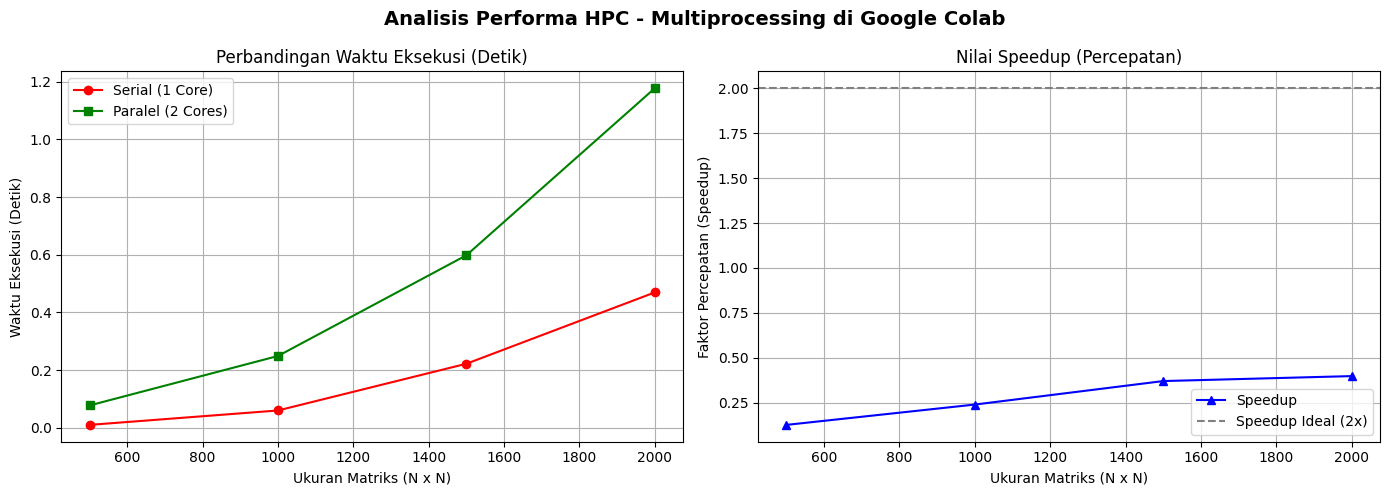

In [6]:
import matplotlib.pyplot as plt

def run_hpc_benchmark():
    matrix_sizes = [500, 1000, 1500, 2000]
    num_cores = os.cpu_count()

    time_serial_list = []
    time_parallel_list = []
    speedup_list = []
    gflops_parallel_list = []

    print(f"--- MULAI BENCHMARK HPC (Menggunakan {num_cores} Cores) ---\n")

    for N in matrix_sizes:
        print(f"Memproses Matriks Ukuran: {N} x {N}...")

        # Inisialisasi matriks acak ber tipe float64
        np.random.seed(42)
        A = np.random.rand(N, N)
        B = np.random.rand(N, N)

        # 1. Eksekusi Serial
        _, t_serial = matrix_multiply_serial(A, B)
        time_serial_list.append(t_serial)

        # 2. Eksekusi Paralel
        _, t_parallel = matrix_multiply_parallel(A, B, num_workers=num_cores)
        time_parallel_list.append(t_parallel)

        # 3. Hitung Speedup & GFLOPS
        speedup = t_serial / t_parallel if t_parallel > 0 else 0
        speedup_list.append(speedup)

        gflops_par = calculate_gflops(N, t_parallel)
        gflops_parallel_list.append(gflops_par)

        print(f"  > Waktu Serial   : {t_serial:.4f} detik")
        print(f"  > Waktu Paralel  : {t_parallel:.4f} detik")
        print(f"  > Speedup        : {speedup:.2f}x lebih cepat")
        print(f"  > Performansi    : {gflops_par:.2f} GFLOPS\n")

    # --- PLOTTING GRAFIK ---
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Grafik 1: Perbandingan Waktu Eksekusi
    ax1.plot(matrix_sizes, time_serial_list, marker='o', color='red', label='Serial (1 Core)')
    ax1.plot(matrix_sizes, time_parallel_list, marker='s', color='green', label=f'Paralel ({num_cores} Cores)')
    ax1.set_title('Perbandingan Waktu Eksekusi (Detik)')
    ax1.set_xlabel('Ukuran Matriks (N x N)')
    ax1.set_ylabel('Waktu Eksekusi (Detik)')
    ax1.grid(True)
    ax1.legend()

    # Grafik 2: Nilai Speedup (Akselerasi)
    ax2.plot(matrix_sizes, speedup_list, marker='^', color='blue', label='Speedup')
    ax2.axhline(y=num_cores, color='gray', linestyle='--', label=f'Speedup Ideal ({num_cores}x)')
    ax2.set_title('Nilai Speedup (Percepatan)')
    ax2.set_xlabel('Ukuran Matriks (N x N)')
    ax2.set_ylabel('Faktor Percepatan (Speedup)')
    ax2.grid(True)
    ax2.legend()

    plt.suptitle("Analisis Performa HPC - Multiprocessing di Google Colab", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Jalankan Benchmark
run_hpc_benchmark()